In [12]:
from src.LearnedTikhonov import LearnedTikhonov, train
from src.print_utils import print_kv, print_section
from src.Heat1DCrankNicolson import Heat1DCrankNicolson
from src.TikhonovHandler import TikhonovHandler
from src.NoiseGenerator import NoiseGenerator, print_noise_stats, apply_noise_to_dataset
from typing import Literal, get_args, Tuple
from src.LoadingHandler import load_dataset, load_impulse_response, load_simulation_info

import torch
import torch.nn as nn
import h5py
import matplotlib.pyplot as plt
import numpy as np


plt.style.use("styles/plots.mplstyle")

1. TRAINING

def smoothness_regularization(model: LearnedTikhonov) -> torch.Tensor:
    """Penalize sharp variations in R and Phi"""
    dR   = model._get_R()[1:]   - model._get_R()[:-1]
    dPhi = model._get_phi()[1:] - model._get_phi()[:-1]
    return (dR ** 2).mean() + (dPhi ** 2).mean()

_TYPES = Literal["ReduceLR", "Cosine"]

def train(
    model: LearnedTikhonov,
    G_train: torch.Tensor,
    F_train: torch.Tensor,
    G_val:   torch.Tensor,
    F_val:   torch.Tensor,
    n_epochs: int        = 2000,
    lr: float            = 1e-3,
    weight_decay: float  = 0.0,
    checkpoint_path: str = "assets/tikhonov_learned/best_tikhonov.pt",
    scheduler_patience: int   = 50,
    scheduler_factor:   float = 0.5,
    log_every: int       = 50,
    lambda_smooth: float = 0,
    scheduler_type: _TYPES = "Cosine",
    min_mse_index: int = 0,
    max_mse_index: int = -1
) -> dict:
    """Train LearnedTikhonov model with various options."""
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    options = get_args(_TYPES)
    assert scheduler_type in options, f"'{scheduler_type}' is not in {options}"
    
    if scheduler_type == "Cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=2000, T_mult=2, eta_min=1e-6
        )
    elif scheduler_type == "ReduceLR":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", patience=scheduler_patience, factor=scheduler_factor
        )

    loss_fn = nn.MSELoss()
    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_val = float("inf")

    for epoch in range(1, n_epochs + 1):
        # Training Step
        model.train()
        optimizer.zero_grad()
        
        pred_train = model(G_train)
        mse_train = loss_fn(pred_train[:,min_mse_index:max_mse_index], F_train[:,min_mse_index:max_mse_index])
        loss_train = mse_train
        
        if lambda_smooth != 0:
            reg_smooth = smoothness_regularization(model)
            loss_train += lambda_smooth * reg_smooth
        
        loss_train.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        # Validation Step
        model.eval()
        with torch.no_grad():
            pred_val = model(G_val)
            mse_val = loss_fn(pred_val[:,min_mse_index:max_mse_index], F_val[:,min_mse_index:max_mse_index])
            loss_val = mse_val
            
            if lambda_smooth != 0:
                reg_smooth = smoothness_regularization(model)
                loss_val += lambda_smooth * reg_smooth

        train_l = loss_train.item()
        val_l = loss_val.item()
        scheduler.step(epoch)
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)

        if val_l < best_val:
            best_val = val_l
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "val_loss": best_val,
            }, checkpoint_path)

        if epoch % log_every == 0 or epoch == 1:
            print(f"Epoch {epoch:5d}/{n_epochs} | train MSE: {train_l:.4e} | "
                  f"val MSE: {val_l:.4e} | lr: {current_lr:.2e}")

    print_kv(f"Best val MSE", f"{best_val:.4e}, saved to {checkpoint_path}")
    return history

2. PLOTTING and UTILS

In [13]:
def compute_mse_t(f_pred, f_true):
    return np.mean((f_pred - f_true) ** 2, axis=0)

def plot_diagnostics(model: LearnedTikhonov, omegas: np.ndarray, tikh_w: np.ndarray = None,
                    save_path: str = "diagnostics.pdf"):
    """Plot learned R, Phi, and comparison with Tikhonov."""
    fig, axes = plt.subplots(3, 1, figsize=(3.2, 3.6), sharex=True)
    ax1, ax2, ax3 = axes
    
    ax1.plot(omegas, model.get_phi(), color="steelblue", lw=1.5)
    ax1.set_ylabel(r"$\phi$")
    ax1.set_title(r"Learned model")
    ax1.set_ylim([-3.3, 3.3])
    ax1.grid(True, alpha=0.3)
    
    ax2.semilogy(omegas, model.get_R(), color="darkorange", lw=1)
    ax2.set_ylabel(r"$R$")
    ax2.grid(True, alpha=0.3)

    ax3.semilogy(omegas, model.get_W_magnitude(), color="r", lw=1, label=r"Learned $|\Lambda|$")
    if tikh_w is not None:
        ax3.semilogy(omegas, np.abs(tikh_w), color="b", lw=1, alpha=1,ls="--", label=r"Tikhonov $|\Lambda|$")
    
    ax3.set_ylabel(r"$|\Lambda|$")
    ax3.set_xlabel(r"$\omega$")
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print_kv(f"Diagnostic saved", f"{save_path}")


def plot_history(history: dict, save_path: str = "loss_history.pdf"):
    """Plot training history."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots()
    
    ax.semilogy(epochs, history["train_loss"], label="Train MSE")
    ax.semilogy(epochs, history["val_loss"], label="Val MSE", ls="--")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title("Loss curve")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print_kv(f"Loss history saved", f"{save_path}")


def plot_prediction_RPM(model: LearnedTikhonov,
                   G_val: torch.Tensor,
                   F_val: torch.Tensor,
                   n_samples: int = 3,
                   save_path: str = "predictions.pdf",
                   min_mse_index: int = 0,
                   max_mse_index: int = -1):
    model.eval()
    with torch.no_grad():
        f_pred = model(G_val).cpu().numpy()
    f_true = F_val.cpu().numpy()
    
    plot_prediction(G_val,f_true,f_pred,model_name="RPM",n_samples=n_samples, save_path=save_path, min_mse_index=min_mse_index, max_mse_index=max_mse_index)
    
def plot_prediction(G_val: torch.Tensor,
                   f_true,
                   f_pred,
                   n_samples: int = 3,
                   model_name: str = "Tikhonov",
                   save_path: str = "predictions.pdf",
                   min_mse_index: int = 0,
                   max_mse_index: int = -1):
    nt = f_true.shape[1]
    t = np.arange(nt)

    n_show = min(n_samples, len(f_true))
    fig, axes = plt.subplots(n_show, 1, figsize=(3.2, 1.2 * n_show), sharex=True)
    if n_show == 1:
        axes = [axes]

    G_array = G_val.cpu().numpy()
    mse_array = np.mean((f_pred[:,min_mse_index:max_mse_index] - f_true[:,min_mse_index:max_mse_index]) ** 2, axis=1)
    
    for i, ax in enumerate(axes):
        ax.plot(t, G_array[i], label=r"$g_{obs}$",ls="-.", c="k")
        ax.plot(t, f_true[i], label=r"$f_{true}$", lw=3, c="b", alpha=0.5)
        ax.plot(t, f_pred[i], label=r"$f_{rec}$",ls="--", c="r")
        
        mse_i = mse_array[i]
        ax.text(0.12, 0.15, f"MSE = {mse_i:.3e}",
                transform=ax.transAxes, verticalalignment='top')
        
        ax.set_ylabel(r"$\Theta$")
        ax.grid(True, alpha=0.3)
        ax.set_ylim([-5, 5])
        
        if min_mse_index > 0:
            ax.axvline(x=min_mse_index, ls="--", c="k", alpha=0.5)
        if max_mse_index < -1:
            ax.axvline(x=nt+max_mse_index, ls="--", c="k", alpha=0.5)
        
        ax.minorticks_on()

    axes[0].legend(loc="upper center", ncols=3)
    axes[-1].set_xlabel("Sample")
    axes[0].set_title(model_name + f" - MSE: {np.mean(mse_array):.3e}")
    
    print_kv("Val MSE (RPM):", f"{np.mean(mse_array):.3e}")
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print_kv(f"Predictions saved", f"{save_path}")
    
def plot_mse_t_comparison(
                f_true,
                f_pred_th,
                f_pred_rpm,
                mst_path: str = "",
                save_path: str = "mse_t_comparison.pdf",
                min_mse_index: int = 0,
                max_mse_index: int = -1):

    nt = f_true.shape[1]
    t = np.arange(nt)
        
    mse_t_th = compute_mse_t(f_pred_th,f_true)
    mse_t_rpm = compute_mse_t(f_pred_rpm,f_true)

    plt.ylabel(r"$MSE_t$")
    plt.xlabel(r"Sample")
    plt.plot(t,mse_t_th, label=r"Tikhonov")
    plt.plot(t,mse_t_rpm, label=r"RPM")
    plt.legend()
    plt.grid()
    plt.title(r"$MSE_t$ comparison between RPM and Tikhonov")
    plt.yscale("log")
    
    if min_mse_index > 0:
        plt.axvline(x=min_mse_index, ls="--", c="k", alpha=0.5)
    if max_mse_index < -1:
        plt.axvline(x=nt+max_mse_index, ls="--", c="k", alpha=0.5)
            
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()
    print_kv(f"Predictions saved", f"{save_path}")
    
    if mst_path != "":
        np.savetxt(mst_path, (mse_t_rpm,mse_t_th), delimiter=';')

3. CONFIGURATION & PARAMETERS

In [14]:
# Dataset configuration
DATASET_CODE = "lru5_20_noise_25_correlated/"     # Change this for different datasets
VAL_FRACTION = 0.1
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

4. DATA LOADING

def load_simulation_info(dataset_code: str) -> Tuple[float, float, int, float, float, float, float, float]:
    """Load simulation parameters from CSV."""
    L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
        f"dataset/{dataset_code}simulation_info.csv", delimiter=";", usecols=1
    )
    return L, Tf, int(nt), D, h_param, l, r, Tf / int(nt)

def load_impulse_response(dataset_code: str, n: int, dt: float) -> Tuple[np.ndarray, int, np.ndarray]:
    """Load and FFT impulse response."""
    h_vals = np.loadtxt(f"dataset/{dataset_code}impulse_response.csv", delimiter=";")
    H_np = np.fft.rfft(h_vals, n).astype(np.complex64)
    nk = len(H_np)
    omegas = np.fft.rfftfreq(n, d=dt) * 2 * np.pi
    return H_np, nk, omegas

def load_dataset(dataset_code: str) -> Tuple[np.ndarray, np.ndarray]:
    """Load f and g from HDF5"""
    H5_PATH = f"dataset/{dataset_code}dataset.h5"
    with h5py.File(H5_PATH, "r") as hf:
        data = hf["dataset"][:]  # (N, 2, nt)
    
    f_all = data[:, 0, :].astype(np.float32)
    g_all = data[:, 1, :].astype(np.float32)
    return f_all, g_all

In [15]:
print_section("LOADING DATA")

# Load simulation parameters
L, Tf, nt, D, h_param, l, r, dt = load_simulation_info(DATASET_CODE)
n = int(2 * nt - 1)

# Load impulse response
H_np, nk, omegas = load_impulse_response(DATASET_CODE, n, dt)
print_kv("Impulse response", f"nk={nk}, n={n}")

# Load dataset
f_all, g_all = load_dataset(DATASET_CODE)
N = len(f_all)
print_kv("Dataset", f"N={N}, nt={nt}")


-----------------------------LOADING DATA-----------------------------

Impulse response                                       nk=2000, n=3999
Dataset                                                N=1000, nt=2000


In [16]:
# Noise configuration - CHOOSE YOUR SCENARIO HERE
NOISE_CONFIG = {
    "noise_level": 0.25,                    # 0-1, e.g., 0.05 = 5%
    "noise_type": "correlated",                 # Choose: "white", "correlated", "lowfreq_systematic", "multiplicative", "pink", "brown", "thermal"
    "apply_delay": False,
    "rolling": 100,                          # Number of samples to roll (delay)
}

# Training configuration
TRAINING_CONFIG = {
    "perform_training": True,
    "n_epochs": 5000,
    "lr": 1e-3,
    "weight_decay": 0.0,
    "scheduler_type": "Cosine",
    "log_every": 100,
    "lambda_smooth": 0,                     # Smoothness regularization weight
    "mult_factor_diffusion_time": 1.5,
    "learn_phi": True,
    "learn_R": True,
    "min_omega": 0,
    "max_omega":np.max(omegas)
}

In [17]:
print_section("NOISE CONFIGURATION")

noise_level = NOISE_CONFIG["noise_level"]
noise_type = NOISE_CONFIG["noise_type"]

print_kv("Noise type", noise_type)
print_kv("Noise level", f"{noise_level*100:.1f}%")

if noise_level > 0:
    generator = NoiseGenerator(seed=SEED)
    g_all, noise = generator.apply_noise(g_all, noise_level, noise_type)
    print_noise_stats(noise, noise_type)
else:
    print_kv("Status", "No noise applied (clean data)")

# Apply delay if needed
if NOISE_CONFIG["apply_delay"] and NOISE_CONFIG["rolling"] != 0:
    rolling = NOISE_CONFIG["rolling"]
    g_rolled = np.roll(g_all, rolling, axis=1)
    g_rolled[:, :rolling] = 0
    g_all = g_rolled
    print_kv("Time delay applied", f"{rolling} samples = {rolling*dt:.4e} s")


-------------------------NOISE CONFIGURATION--------------------------

Noise type                                                  correlated
Noise level                                                      25.0%

CORRELATED
Mean                                                       -1.6046e-03
Std                                                         1.5284e-01
Max                                                         1.1350e+00
Energy                                                      4.6728e+04


In [18]:
print_section("DATASET SPLIT")

rng = np.random.default_rng(SEED)
idx = rng.permutation(N)
n_val = max(1, int(VAL_FRACTION * N))
idx_val = idx[:n_val]
idx_train = idx[n_val:]

print_kv("Dataset split", f"total={N}, train={len(idx_train)}, val={n_val}")
print_kv("Device", DEVICE)

G_train = torch.from_numpy(g_all[idx_train]).to(DEVICE)
F_train = torch.from_numpy(f_all[idx_train]).to(DEVICE)
G_val = torch.from_numpy(g_all[idx_val]).to(DEVICE)
F_val = torch.from_numpy(f_all[idx_val]).to(DEVICE)


----------------------------DATASET SPLIT-----------------------------

Dataset split                                total=1000, train=900, val=100
Device                                                            cuda


In [19]:
# Initialize solver for comparison
solver = Heat1DCrankNicolson(L=L, Tf=Tf, nt=nt, D=D, h=h_param, wanted_r=r)
solver.info()
th = TikhonovHandler(solver)

#NOTE: Da togliere
#plt.plot(H_np)
#H_np = np.fft.rfft(solver.impulse_response()[-1,:], n).astype(np.complex64)
#plt.plot(H_np)

# Compute and estimation for the best lambda 
f_true = F_val.cpu().numpy()
G_val_np = G_val.cpu().numpy()
lambda_mean = 0
for i in range(5):
    lambda_mean += th.best_lambda(G_val_np[i])

nt = f_true.shape[1]
t = np.arange(nt)

best_lambda=lambda_mean/3
print_kv("Best Lambda estimate:", f"{best_lambda:.3e}")


-----------------------------Solver info------------------------------

Diffusion time:                                               1.00e+00
dx:                                                           8.33e-02
dt:                                                           5.00e-03
nt:                                                               2000
nx:                                                                 13
r:                                                            7.20e-01
h:                                                            1.00e+00
Best Lambda estimate:                                        9.540e+00


In [20]:
print_section("DIFFUSION TIME EVALUATION")

from scipy.optimize import brentq

def f_eigen(x, h, L):
    return x + h * np.tan(x * L)

def trova_radici(h, L, n_radici):
    radici = []
    k = 0
    while len(radici) < n_radici:
        # Per x + h*tan(xL)=0 con h>0 le radici stanno dove tan < 0,
        # cioè in ( (2k+1)Pi/(2L) , (k+1)Pi/L )
        left_asym  = (2*k + 1) * np.pi / (2*L)   # asintoto sinistro
        right_zero = (k + 1)   * np.pi / L        # zero di tan
        
        a = left_asym  + 1e-9
        b = right_zero - 1e-9

        try:
            fa, fb = f_eigen(a, h, L), f_eigen(b, h, L)
            if fa * fb < 0:
                root = brentq(f_eigen, a, b, args=(h, L))
                radici.append(root)
        except Exception:
            pass
        k += 1
    return np.array(radici)

lamb_0 = trova_radici(h_param, L, 1)[0]
diffusion_time_0 = TRAINING_CONFIG["mult_factor_diffusion_time"]/(D*lamb_0*lamb_0)
diffusion_time_0_inSample = int(diffusion_time_0 / dt)

print_kv("lambda_0:",f"{lamb_0:.6f}")
print_kv("diffusion_time_0:",f"{diffusion_time_0:.6f}")
print_kv("diffusion_time_0_inSample:",f"{diffusion_time_0_inSample}")

min_mse_index = diffusion_time_0_inSample
max_mse_index = -diffusion_time_0_inSample

if NOISE_CONFIG["apply_delay"] == True:
    min_mse_index = min_mse_index + NOISE_CONFIG["rolling"]
    max_mse_index = max_mse_index - NOISE_CONFIG["rolling"]
    
if max_mse_index == 0:
    max_mse_index = -1

'''
min_mse_index = -diffusion_time_0_inSample
max_mse_index = -1
'''

print_kv("min_mse_index:",f"{min_mse_index}")
print_kv("max_mse_index:",f"{max_mse_index}")


----------------------DIFFUSION TIME EVALUATION-----------------------

lambda_0:                                                     2.028758
diffusion_time_0:                                             0.364444
diffusion_time_0_inSample:                                          72
min_mse_index:                                                      72
max_mse_index:                                                     -72


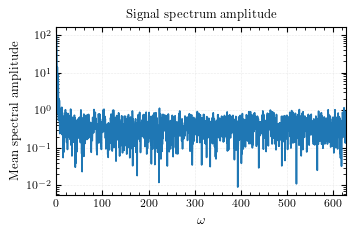


-------------------------MODEL INITIALIZATION-------------------------

Phi                                    phi  : 2000/2000, Trained: True
R                                      log_R: 2000/2000, Trained: True


In [21]:
model = LearnedTikhonov(H=H_np, n=n, nt=nt, dt=dt, lambda_tik=best_lambda).to(DEVICE)

if not TRAINING_CONFIG["learn_phi"]:
    model.freeze_phi()
    
if not TRAINING_CONFIG["learn_R"]:
    model.freeze_R()
    
plt.figure(1)
g_fft = np.fft.rfft(G_val.cpu(),n)
g_fft = np.mean(g_fft,axis=0)
plt.plot(omegas, np.abs(g_fft))
plt.xlim([TRAINING_CONFIG["min_omega"],TRAINING_CONFIG["max_omega"]])
plt.ylabel(r"Mean spectral amplitude")
plt.xlabel(r"$\omega$")
plt.title("Signal spectrum amplitude")
plt.minorticks_on()
plt.grid()
plt.yscale("log")
plt.show()
plt.savefig(f"assets/tikhonov_learned/{DATASET_CODE}spectrum.pdf", dpi=150, bbox_inches='tight')
plt.close()

print_section("MODEL INITIALIZATION")

model.set_tainable_range_by_omegas(TRAINING_CONFIG["min_omega"],TRAINING_CONFIG["max_omega"])

n_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print_kv("Phi", f"phi  : {sum(model.phi_mask.cpu())}/{nk}, Trained: {TRAINING_CONFIG['learn_phi']}",value_width=35)
print_kv("R", f"log_R: {sum(model.R_mask.cpu())}/{nk}, Trained: {TRAINING_CONFIG['learn_R']}",value_width=35)



In [22]:
if TRAINING_CONFIG["perform_training"]:
    print_section("TRAINING")
    
    print_section("TRAINING PHI")
    model.unfreeze_phi()
    model.freeze_R()
    
    history = train(
        model=model,
        G_train=G_train,
        F_train=F_train,
        G_val=G_val,
        F_val=F_val,
        n_epochs=TRAINING_CONFIG["n_epochs"],
        lr=TRAINING_CONFIG["lr"],
        weight_decay=TRAINING_CONFIG["weight_decay"],
        checkpoint_path=f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
        scheduler_type=TRAINING_CONFIG["scheduler_type"],
        log_every=TRAINING_CONFIG["log_every"],
        lambda_smooth=TRAINING_CONFIG["lambda_smooth"],
        min_mse_index=min_mse_index,
        max_mse_index=max_mse_index
    )
    
    print_section("TRAINING R")
    model.unfreeze_R()
    model.freeze_phi()
    
    history = train(
            model=model,
            G_train=G_train,
            F_train=F_train,
            G_val=G_val,
            F_val=F_val,
            n_epochs=TRAINING_CONFIG["n_epochs"],
            lr=TRAINING_CONFIG["lr"],
            weight_decay=TRAINING_CONFIG["weight_decay"],
            checkpoint_path=f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
            scheduler_type=TRAINING_CONFIG["scheduler_type"],
            log_every=TRAINING_CONFIG["log_every"],
            lambda_smooth=TRAINING_CONFIG["lambda_smooth"],
            min_mse_index=min_mse_index,
            max_mse_index=max_mse_index,
            history = history
        )
    
    print_section("TRAINING BOTH")
    model.unfreeze_R()
    model.unfreeze_phi()
    
    history = train(
            model=model,
            G_train=G_train,
            F_train=F_train,
            G_val=G_val,
            F_val=F_val,
            n_epochs=TRAINING_CONFIG["n_epochs"],
            lr=TRAINING_CONFIG["lr"],
            weight_decay=TRAINING_CONFIG["weight_decay"],
            checkpoint_path=f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
            scheduler_type=TRAINING_CONFIG["scheduler_type"],
            log_every=TRAINING_CONFIG["log_every"],
            lambda_smooth=TRAINING_CONFIG["lambda_smooth"],
            min_mse_index=min_mse_index,
            max_mse_index=max_mse_index,
            history = history
        )
else:
    print_kv("Training", "Skipped (perform_training=False)")
    history = None


-------------------------------TRAINING-------------------------------


-----------------------------TRAINING PHI-----------------------------

Epoch     1/5000 | train MSE: 6.4056e-02 | val MSE: 6.3578e-02 | lr: 1.00e-03
Epoch   100/5000 | train MSE: 3.9852e-02 | val MSE: 3.9169e-02 | lr: 9.94e-04
Epoch   200/5000 | train MSE: 2.6178e-02 | val MSE: 2.4829e-02 | lr: 9.76e-04
Epoch   300/5000 | train MSE: 2.5797e-02 | val MSE: 2.4507e-02 | lr: 9.46e-04
Epoch   400/5000 | train MSE: 2.5700e-02 | val MSE: 2.4445e-02 | lr: 9.05e-04
Epoch   500/5000 | train MSE: 2.5637e-02 | val MSE: 2.4403e-02 | lr: 8.54e-04
Epoch   600/5000 | train MSE: 2.5583e-02 | val MSE: 2.4364e-02 | lr: 7.94e-04
Epoch   700/5000 | train MSE: 2.5537e-02 | val MSE: 2.4329e-02 | lr: 7.27e-04
Epoch   800/5000 | train MSE: 2.5499e-02 | val MSE: 2.4300e-02 | lr: 6.55e-04
Epoch   900/5000 | train MSE: 2.5468e-02 | val MSE: 2.4275e-02 | lr: 5.79e-04
Epoch  1000/5000 | train MSE: 2.5444e-02 | val MSE: 2.4255e-02 | lr: 5.01e

KeyboardInterrupt: 

In [ ]:
print_section("DIAGNOSTICS RPM")

# Load trained model
ckpt = torch.load(f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt", 
                    map_location="cpu")
model.load_state_dict(ckpt["model_state"])
model.to("cpu")

# Plot diagnostics
plot_diagnostics(model, omegas, th._build_W(best_lambda),
                save_path=f"assets/tikhonov_learned/{DATASET_CODE}diagnostics.pdf")

if history is not None:
    plot_history(history, 
                save_path=f"assets/tikhonov_learned/{DATASET_CODE}loss_history.pdf")

# Plot predictions
plot_prediction_RPM(model, G_val.cpu(), F_val.cpu(),
                n_samples=7,
                save_path=f"assets/tikhonov_learned/{DATASET_CODE}predictions_RPM.pdf",
                min_mse_index=min_mse_index,
                max_mse_index=max_mse_index)

# 6.394e-02
# 6.072e-01


---------------------------DIAGNOSTICS RPM----------------------------

Diagnostic saved                             assets/tikhonov_learned/lru5_20_noise_25_correlated/diagnostics.pdf
Loss history saved                           assets/tikhonov_learned/lru5_20_noise_25_correlated/loss_history.pdf
Val MSE (RPM):                                               2.446e-03
Predictions saved                            assets/tikhonov_learned/lru5_20_noise_25_correlated/predictions_RPM.pdf


In [ ]:
f_pred_th = np.ndarray(np.shape(f_true))
i = 0
for G in G_val_np:
    f_pred_th[i] = (th.regularize(G, lambda_reg=best_lambda, regularization_type_="closed"))
    i = i + 1

model.eval()
with torch.no_grad():
    f_pred_rpm = model(G_val.cpu()).cpu().numpy()
        
plot_mse_t_comparison(f_true,f_pred_th,f_pred_rpm,
                save_path=f"assets/tikhonov_learned/{DATASET_CODE}mse_t_comparison.pdf",
                mst_path=f"assets/tikhonov_learned/{DATASET_CODE}mse_t.csv",
                min_mse_index=min_mse_index,
                max_mse_index=max_mse_index)

Predictions saved                            assets/tikhonov_learned/lru5_20_noise_25_correlated/mse_t_comparison.pdf


In [ ]:
plot_prediction(G_val.cpu(),f_true,f_pred_th,n_samples=7,
                save_path=f"assets/tikhonov_learned/{DATASET_CODE}predictions_Tikh.pdf",
                min_mse_index=min_mse_index,
                max_mse_index=max_mse_index)

Val MSE (RPM):                                               6.362e-02
Predictions saved                            assets/tikhonov_learned/lru5_20_noise_25_correlated/predictions_Tikh.pdf


In [ ]:
if NOISE_CONFIG["apply_delay"] == True:

    print_section("Phase extraction")
    plt.figure(2)
    dw=omegas[1]-omegas[0]

    # Fit lineare: phi = m * omega + q
    m, q = np.polyfit(omegas[0:int(3/dw)], model.get_phi()[0:int(3/dw)], 1)
    print(int(6/dt))
    # Curva fittata
    phi_fit = m * omegas + q
    print(f"Pendenza = {m:.6f}")

    plt.plot(omegas, phi_fit, '-.', label=fr'Fit: $\phi={m:.3f}\omega+{q:.3f}$', c="k")
    plt.plot(omegas, model.get_phi())
    plt.xlim([0,10])
    plt.ylim([-4.5, 4.5])
    plt.gca().axhline(np.pi, ls="--", c="k", alpha=0.5)
    plt.gca().axhline(-np.pi, ls="--", c="k", alpha=0.5)
    plt.xlabel(r"$\omega$")
    plt.ylabel(r"$\phi$")
    plt.title(r"$\phi$ linear fit in the signal spectrum region")
    plt.legend()
    plt.minorticks_on()
    plt.grid()
    plt.savefig(f"assets/tikhonov_learned/{DATASET_CODE}linear_fit_phi.pdf", dpi=150, bbox_inches='tight')